In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lmfit import models
from scipy.optimize import leastsq
from scipy.optimize import curve_fit
import os
import pandas as pd

In [5]:
def fit_lorentz(
    x, y,
    N,
    title="Lorentz fit",
    sigma=None,
    show_plot=True
):
    """
    Fit N Lorentz-pieken + lineaire trend (a*x + b) op x,y data.

    Parameters:
        x, y        : array-like met de data
        N           : aantal Lorentz-pieken
        title       : titel van de plot
        sigma       : meetonzekerheid van y. Als None, geschat uit residuen.
        show_plot   : True -> plot tonen

    Returns:
        dict met popt, perr, chi2_red, chi2, dof, fig, ax, y_fit
    """

    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    # ── Model: N Lorentzians + lineaire achtergrond ───────────────────────────
    def lorentz(x, x0, gamma, A):
        return A * (gamma**2) / ((x - x0)**2 + gamma**2)

    def multi_lorentz_linear(x, *params):
        # params = [x0_1, gamma_1, A_1, ..., x0_N, gamma_N, A_N, a, b]
        a = params[-2]   # helling
        b = params[-1]   # intercept
        y = a * x + b
        for i in range(0, len(params) - 2, 3):
            y = y + lorentz(x, params[i], params[i+1], params[i+2])
        return y

    # ── Automatische piek-detectie ────────────────────────────────────────────
    # Verwijder lineaire trend voor piekdetectie
    lin_coeff = np.polyfit(x, y, 1)
    y_detrended = y - np.polyval(lin_coeff, x)

    prominence = 0.05 * np.max(np.abs(y_detrended))
    if prominence <= 0:
        prominence = None

    peaks, _ = find_peaks(np.abs(y_detrended), prominence=prominence)

    if len(peaks) < N:
        print(f"Waarschuwing: slechts {len(peaks)} pieken gevonden, N teruggebracht naar {len(peaks)}.")
        N = len(peaks)

    # Sorteer op amplitude, pak de N grootste
    sort_idx = np.argsort(np.abs(y_detrended[peaks]))[::-1]
    peaks_top = peaks[sort_idx[:N]]
    peaks_top = peaks_top[np.argsort(x[peaks_top])]  # op x-volgorde

    x0_list = x[peaks_top].tolist()
    A_list  = y_detrended[peaks_top].tolist()

    # Gamma-guess: heuristiek op basis van gemiddelde x-stap
    dx = np.mean(np.diff(x))
    gamma_guess = 5 * dx

    # ── p0 opbouwen ───────────────────────────────────────────────────────────
    p0 = []
    for x0, A in zip(x0_list, A_list):
        p0.extend([x0, gamma_guess, A])
    p0.append(lin_coeff[0])   # a (helling)
    p0.append(lin_coeff[1])   # b (intercept)

    # ── Fit ───────────────────────────────────────────────────────────────────
    popt, pcov = curve_fit(multi_lorentz_linear, x, y, p0=p0, maxfev=1000000)
    perr  = np.sqrt(np.diag(pcov))
    y_fit = multi_lorentz_linear(x, *popt)

    # ── Gereduceerde chi-kwadraat ─────────────────────────────────────────────
    residuen = y - y_fit
    if sigma is None:
        sigma_est = np.std(residuen)
    else:
        sigma_est = sigma

    n_params = len(popt)
    dof      = len(y) - n_params
    chi2     = np.sum((residuen / sigma_est) ** 2)
    chi2_red = chi2 / dof

    # ── Resultaten printen ────────────────────────────────────────────────────
    print(f"{'─'*55}")
    print(f"Aantal pieken (N)  = {N}")
    print(f"Chi²               = {chi2:.4f}")
    print(f"Vrijheidsgraden    = {dof}")
    print(f"Gereduceerde Chi²  = {chi2_red:.4f}")
    print(f"{'─'*55}")
    for i in range(N):
        idx = 3 * i
        print(f"Piek {i+1}:")
        print(f"  x0    = {popt[idx]:.6g} ± {perr[idx]:.6g}")
        print(f"  gamma = {popt[idx+1]:.6g} ± {perr[idx+1]:.6g}")
        print(f"  A     = {popt[idx+2]:.6g} ± {perr[idx+2]:.6g}")
    print(f"Lineaire trend: a = {popt[-2]:.6g} ± {perr[-2]:.6g}")
    print(f"               b = {popt[-1]:.6g} ± {perr[-1]:.6g}")
    print(f"{'─'*55}")

    # ── Plot ──────────────────────────────────────────────────────────────────
    fig, ax = None, None
    if show_plot:
        fig, ax = plt.subplots(figsize=(12, 5))
        ax.plot(x, y, 'g.', ms=3, label="Data")
        ax.plot(x, y_fit, 'r-', lw=1.5, label="Totale fit")

        # Lineaire achtergrond
        y_lin = popt[-2] * x + popt[-1]
        ax.plot(x, y_lin, 'k--', lw=1, label="Lineaire trend")

        # Individuele pieken
        for i in range(N):
            idx = 3 * i
            x0_i, g_i, A_i = popt[idx], popt[idx+1], popt[idx+2]
            y_i = lorentz(x, x0_i, g_i, A_i) + y_lin
            ax.plot(x, y_i, '--', lw=1, label=f"Piek {i+1}")

        ax.set_xlabel("x")
        ax.set_ylabel("y")
        ax.set_title(title)
        ax.legend()
        plt.tight_layout()
        plt.show()

    return {
        "popt"    : popt,
        "perr"    : perr,
        "chi2_red": chi2_red,
        "chi2"    : chi2,
        "dof"     : dof,
        "fig"     : fig,
        "ax"      : ax,
        "x"       : x,
        "y"       : y,
        "y_fit"   : y_fit
    }

───────────────────────────────────────────────────────
Bestand: /Users/timwiemer/Desktop/Natuur  en Sterrenkunde/Jaar 1/Rubium_Spectroscopy_group_11/Data/Full_spectrum_avg_4_2026_06_17/TEK0000.CSV
Aantal pieken (N)  = 4
Chi²               = 2231.0000
Vrijheidsgraden    = 2218
Gereduceerde Chi²  = 1.0059
───────────────────────────────────────────────────────
Piek 1:
  x0    = -0.0120341 ± 1.55467e-05
  gamma = 0.00106015 ± 3.19086e-05
  A     = -0.0576213 ± 0.000886452
Piek 2:
  x0    = 0.00351094 ± 0.079751
  gamma = 0.0198505 ± 0.193957
  A     = 5.37397 ± 6217.37
Piek 3:
  x0    = 0.000551939 ± 4.72795e-05
  gamma = 0.00210212 ± 0.000174493
  A     = -0.0315586 ± 0.00218633
Piek 4:
  x0    = 0.0036513 ± 0.0816664
  gamma = 0.0201891 ± 0.195505
  A     = -5.48153 ± 6217.36
Achtergrond B = 0.242363 ± 0.0063521
───────────────────────────────────────────────────────


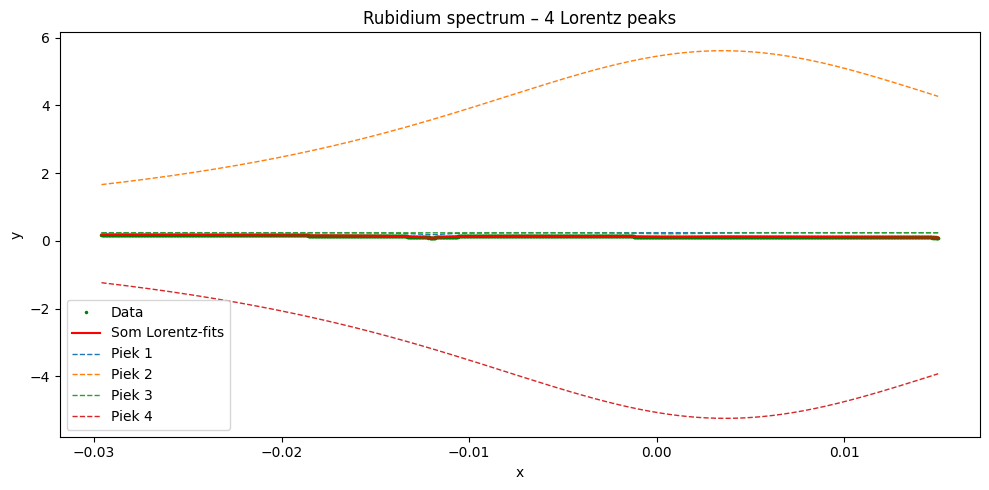

Gereduceerde chi² = 1.0058611363329355


In [ ]:
result = fit_lorentz(x_avg_1, y_avg_1, N=4, title="Piek 1 gemiddeld")

# Parameters opvragen:
popt     = result["popt"]
perr     = result["perr"]
chi2_red = result["chi2_red"]

# Plot achteraf aanpassen:
result["ax"].set_title("Nieuwe titel")
result["fig"].savefig("fit.png", dpi=300)